In [1]:
import os
import sys
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import shap
import matplotlib.pyplot as plt

print("SHAP version:", shap.__version__)
print("Libraries imported successfully.")

SHAP version: 0.46.0
Libraries imported successfully.


In [9]:
ML_DIR = Path.cwd().parent

MODEL_PATH = ML_DIR / "models" / "paysim_xgboost.pkl"
FEATURE_PATH = ML_DIR / "models" / "paysim_features.txt"
DATA_PATH = ML_DIR / "data" / "paysim_processed.csv"
REPORT_DIR = ML_DIR / "reports" / "shap"

REPORT_DIR.mkdir(parents=True, exist_ok=True)

print("ML directory:", ML_DIR)
print("Model exists:", MODEL_PATH.exists())
print("Feature file exists:", FEATURE_PATH.exists())
print("Processed dataset exists:", DATA_PATH.exists())

ML directory: /Users/harshitgoyal/Desktop/UCS503P/finshield_ai/code/ml
Model exists: True
Feature file exists: True
Processed dataset exists: True


In [3]:
model = joblib.load(MODEL_PATH)

print("Model loaded successfully.")
print("Model type:", type(model))

Model loaded successfully.
Model type: <class 'xgboost.sklearn.XGBClassifier'>


/opt/anaconda3/envs/eeg_pd/lib/python3.10/site-packages/xgboost/core.py:158: UserWarning: [21:19:08] WARNING: /Users/runner/work/xgboost/xgboost/src/gbm/../common/error_msg.h:80: If you are loading a serialized model (like pickle in Python, RDS in R) or
configuration generated by an older version of XGBoost, please export the model by calling
`Booster.save_model` from that version first, then load it back in current version. See:

    https://xgboost.readthedocs.io/en/stable/tutorials/saving_model.html

for more details about differences between saving model and serializing.

  warnings.warn(smsg, UserWarning)


In [4]:
with open(FEATURE_PATH, "r") as file:
    feature_names = [
        line.strip()
        for line in file
        if line.strip()
    ]

print("Number of features:", len(feature_names))
print(feature_names)

Number of features: 18
['step', 'amount', 'oldbalanceOrg', 'newbalanceOrig', 'oldbalanceDest', 'newbalanceDest', 'isFlaggedFraud', 'origin_balance_change', 'destination_balance_change', 'origin_error', 'destination_error', 'amount_to_origin_balance', 'amount_to_destination_balance', 'type_CASH_IN', 'type_CASH_OUT', 'type_DEBIT', 'type_PAYMENT', 'type_TRANSFER']


In [7]:
df = pd.read_csv(
    DATA_PATH,
    nrows=1000
)

print("Dataset shape:", df.shape)
print(df.head())

Dataset shape: (1000, 11)
   step      type    amount     nameOrig  oldbalanceOrg  newbalanceOrig  \
0     1   PAYMENT   9839.64  C1231006815       170136.0       160296.36   
1     1   PAYMENT   1864.28  C1666544295        21249.0        19384.72   
2     1  TRANSFER    181.00  C1305486145          181.0            0.00   
3     1  CASH_OUT    181.00   C840083671          181.0            0.00   
4     1   PAYMENT  11668.14  C2048537720        41554.0        29885.86   

      nameDest  oldbalanceDest  newbalanceDest  isFraud  isFlaggedFraud  
0  M1979787155             0.0             0.0        0               0  
1  M2044282225             0.0             0.0        0               0  
2   C553264065             0.0             0.0        1               0  
3    C38997010         21182.0             0.0        1               0  
4  M1230701703             0.0             0.0        0               0  


In [11]:
# Create engineered features

df["origin_balance_change"] = (
    df["oldbalanceOrg"] - df["newbalanceOrig"]
)

df["destination_balance_change"] = (
    df["newbalanceDest"] - df["oldbalanceDest"]
)

df["origin_error"] = (
    df["amount"] - df["origin_balance_change"]
)

df["destination_error"] = (
    df["amount"] - df["destination_balance_change"]
)

df["amount_to_origin_balance"] = (
    df["amount"] / (df["oldbalanceOrg"] + 1)
)

df["amount_to_destination_balance"] = (
    df["amount"] / (df["oldbalanceDest"] + 1)
)

print("Engineered features created successfully.")

Engineered features created successfully.


In [12]:
df = pd.get_dummies(
    df,
    columns=["type"],
    prefix="type",
    dtype="int8"
)

print("Transaction types encoded.")
print(df.columns.tolist())

Transaction types encoded.
['step', 'amount', 'nameOrig', 'oldbalanceOrg', 'newbalanceOrig', 'nameDest', 'oldbalanceDest', 'newbalanceDest', 'isFraud', 'isFlaggedFraud', 'origin_balance_change', 'destination_balance_change', 'origin_error', 'destination_error', 'amount_to_origin_balance', 'amount_to_destination_balance', 'type_CASH_IN', 'type_CASH_OUT', 'type_DEBIT', 'type_PAYMENT', 'type_TRANSFER']


In [13]:
if "isFraud" not in df.columns:
    raise ValueError("The dataset must contain the isFraud target.")

missing_features = [
    col for col in feature_names
    if col not in df.columns
]

if missing_features:
    raise ValueError(
        f"Missing model features: {missing_features}"
    )

X = df[feature_names].copy()
y = df["isFraud"].copy()

X = X.replace([np.inf, -np.inf], np.nan)

if X.isna().any().any():
    raise ValueError(
        "Feature data contains missing or infinite values. "
        "Fix them using the same preprocessing rules used in training."
    )

print("Features prepared:", X.shape)
print("Target labels:", y.shape)

Features prepared: (1000, 18)
Target labels: (1000,)


In [14]:
print("Fraud cases:", int((y == 1).sum()))
print("Non-fraud cases:", int((y == 0).sum()))
print("Fraud percentage:", round(float(y.mean() * 100), 4), "%")

Fraud cases: 9
Non-fraud cases: 991
Fraud percentage: 0.9 %


In [15]:
explainer = shap.TreeExplainer(model)

print("SHAP explainer created successfully.")

SHAP explainer created successfully.


In [16]:
X_explain = X.sample(
    n=min(500, len(X)),
    random_state=42
)

shap_values = explainer(X_explain)

print("SHAP calculation completed.")
print("Input shape:", X_explain.shape)
print("SHAP values shape:", shap_values.values.shape)

SHAP calculation completed.
Input shape: (500, 18)
SHAP values shape: (500, 18)


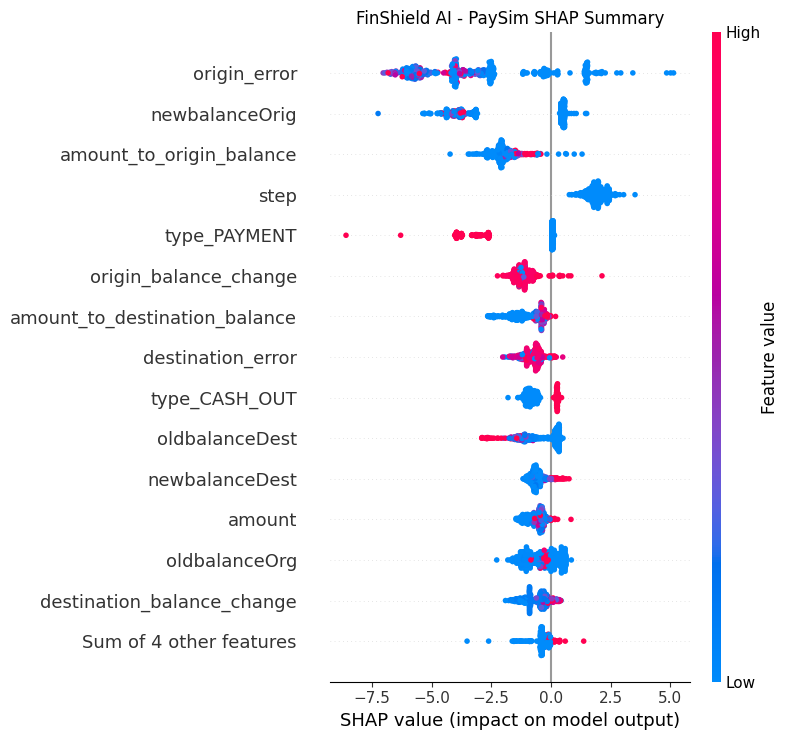

In [17]:
plt.figure()

shap.plots.beeswarm(
    shap_values,
    max_display=15,
    show=False
)

plt.title("FinShield AI - PaySim SHAP Summary")
plt.tight_layout()

plt.savefig(
    REPORT_DIR / "paysim_shap_summary.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

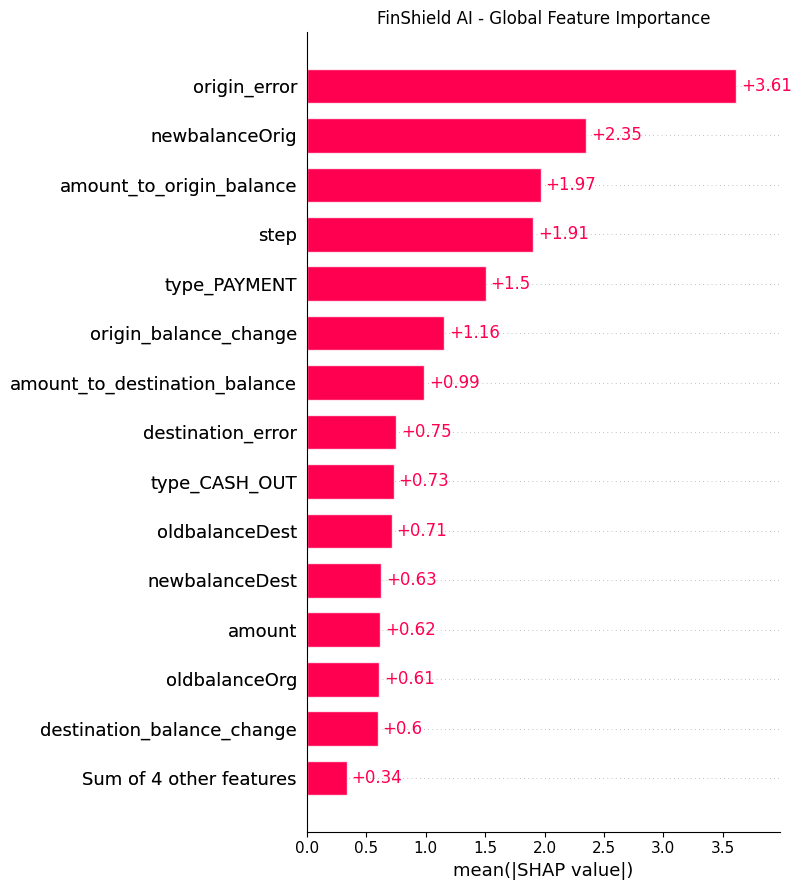

In [18]:
plt.figure()

shap.plots.bar(
    shap_values,
    max_display=15,
    show=False
)

plt.title("FinShield AI - Global Feature Importance")
plt.tight_layout()

plt.savefig(
    REPORT_DIR / "paysim_shap_bar.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

In [19]:
probabilities = model.predict_proba(X_explain)[:, 1]

selected_position = int(np.argmax(probabilities))

transaction_row = X_explain.iloc[[selected_position]]
transaction_probability = float(
    probabilities[selected_position]
)

print("Selected row position:", selected_position)
print("Fraud probability:", round(transaction_probability, 6))
print("Risk score:", round(transaction_probability * 100, 2))

Selected row position: 442
Fraud probability: 0.999993
Risk score: 100.0


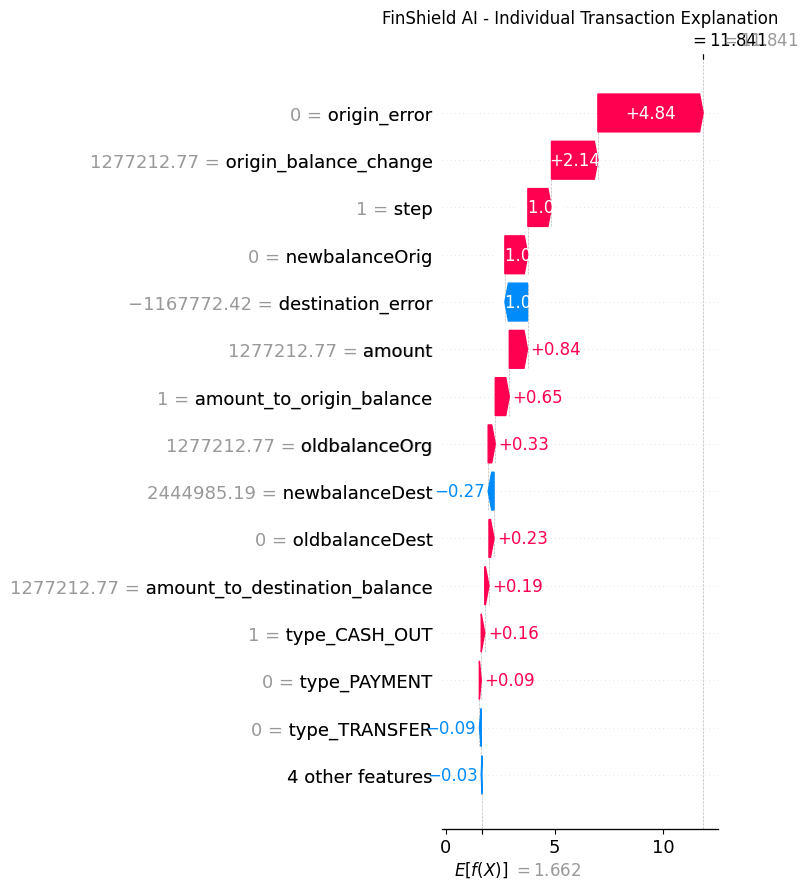

In [20]:
single_explanation = shap_values[selected_position]

shap.plots.waterfall(
    single_explanation,
    max_display=15,
    show=False
)

plt.title("FinShield AI - Individual Transaction Explanation")
plt.tight_layout()

plt.savefig(
    REPORT_DIR / "paysim_single_transaction.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

In [21]:
contributions = pd.DataFrame({
    "feature": feature_names,
    "feature_value": transaction_row.iloc[0].values,
    "shap_value": single_explanation.values
})

contributions["absolute_impact"] = (
    contributions["shap_value"].abs()
)

contributions["direction"] = np.where(
    contributions["shap_value"] > 0,
    "Pushes toward fraud",
    np.where(
        contributions["shap_value"] < 0,
        "Pushes away from fraud",
        "No contribution"
    )
)

contributions = contributions.sort_values(
    "absolute_impact",
    ascending=False
)

display(contributions.head(10))

,feature,feature_value,shap_value,absolute_impact,direction
9,origin_error,0.000000e+00,4.843807,4.843807,Pushes toward fraud
7,origin_balance_change,1.277213e+06,2.136641,2.136641,Pushes toward fraud
0,step,1.000000e+00,1.086799,1.086799,Pushes toward fraud
3,newbalanceOrig,0.000000e+00,1.057809,1.057809,Pushes toward fraud
10,destination_error,-1.167772e+06,-1.041854,1.041854,Pushes away from fraud
1,amount,1.277213e+06,0.838333,0.838333,Pushes toward fraud
11,amount_to_origin_balance,9.999992e-01,0.645839,0.645839,Pushes toward fraud
2,oldbalanceOrg,1.277213e+06,0.327123,0.327123,Pushes toward fraud
5,newbalanceDest,2.444985e+06,-0.270439,0.270439,Pushes away from fraud
4,oldbalanceDest,0.000000e+00,0.232787,0.232787,Pushes toward fraud


In [22]:
contributions.to_csv(
    REPORT_DIR / "paysim_single_transaction_explanation.csv",
    index=False
)

print("Explanation table saved.")

Explanation table saved.


In [32]:
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import shap


# Project paths
ML_DIR = Path(
    "/Users/harshitgoyal/Desktop/UCS503P/finshield_ai/code/ml"
)
MODEL_DIR = ML_DIR / "models"
REPORT_DIR = ML_DIR / "reports" / "shap"

PAYSIM_MODEL = MODEL_DIR / "paysim_xgboost.pkl"
PAYSIM_FEATURES = MODEL_DIR / "paysim_features.txt"

REPORT_DIR.mkdir(parents=True, exist_ok=True)


def load_shap_explainer():
    """Load the trained PaySim model and create its SHAP explainer."""

    model = joblib.load(PAYSIM_MODEL)

    with open(PAYSIM_FEATURES, "r") as file:
        feature_names = [
            line.strip()
            for line in file
            if line.strip()
        ]

    explainer = shap.TreeExplainer(model)

    return model, explainer, feature_names


def explain_transaction(model, explainer, feature_names, transaction_df):
    """
    Explain one already-prepared transaction.

    transaction_df must contain the same features used during training,
    in the same order. It should contain exactly one row.
    """

    if len(transaction_df) != 1:
        raise ValueError("Provide exactly one transaction row.")

    missing = [
        feature for feature in feature_names
        if feature not in transaction_df.columns
    ]

    if missing:
        raise ValueError(f"Missing model features: {missing}")

    X = transaction_df[feature_names].copy()

    X = X.replace([np.inf, -np.inf], np.nan)

    if X.isna().any().any():
        raise ValueError("Transaction contains missing or infinite values.")

    # Calculate the fraud probability
    fraud_probability = float(model.predict_proba(X)[0, 1])

    # Calculate the SHAP explanation
    explanation = explainer(X)

    # Build a readable table
    result = pd.DataFrame({
        "feature": feature_names,
        "feature_value": X.iloc[0].values,
        "shap_value": explanation.values[0]
    })

    result["absolute_impact"] = result["shap_value"].abs()

    result["direction"] = np.select(
        [
            result["shap_value"] > 0,
            result["shap_value"] < 0
        ],
        [
            "Pushes toward fraud",
            "Pushes away from fraud"
        ],
        default="No contribution"
    )

    result = result.sort_values(
        "absolute_impact",
        ascending=False
    ).reset_index(drop=True)

    return {
        "fraud_probability": round(fraud_probability, 6),
        "risk_score": round(fraud_probability * 100, 2),
        "top_features": result.head(10).to_dict(orient="records"),
        "shap_values": explanation
    }


In [34]:
import sys

sys.path.insert(0, str(ML_DIR))

from src.shap_explainer import (
    load_shap_explainer,
    explain_transaction
)

loaded_model, loaded_explainer, loaded_features = (
    load_shap_explainer()
)

test_transaction = X_explain.iloc[[selected_position]]

result = explain_transaction(
    loaded_model,
    loaded_explainer,
    loaded_features,
    test_transaction
)

print("Fraud probability:", result["fraud_probability"])
print("Risk score:", result["risk_score"])

display(pd.DataFrame(result["top_features"]))

Fraud probability: 0.999993
Risk score: 100.0


,feature,feature_value,shap_value,absolute_impact,direction
0,origin_error,0.000000e+00,4.843807,4.843807,Pushes toward fraud
1,origin_balance_change,1.277213e+06,2.136641,2.136641,Pushes toward fraud
2,step,1.000000e+00,1.086799,1.086799,Pushes toward fraud
3,newbalanceOrig,0.000000e+00,1.057809,1.057809,Pushes toward fraud
4,destination_error,-1.167772e+06,-1.041854,1.041854,Pushes away from fraud
5,amount,1.277213e+06,0.838333,0.838333,Pushes toward fraud
6,amount_to_origin_balance,9.999992e-01,0.645839,0.645839,Pushes toward fraud
7,oldbalanceOrg,1.277213e+06,0.327123,0.327123,Pushes toward fraud
8,newbalanceDest,2.444985e+06,-0.270439,0.270439,Pushes away from fraud
9,oldbalanceDest,0.000000e+00,0.232787,0.232787,Pushes toward fraud


In [35]:
import sys
from pathlib import Path

sys.path.insert(0, str(ML_DIR))

print("SHAP file exists:", (ML_DIR / "src" / "shap_explainer.py").exists())
print("ML directory:", ML_DIR)
print("Python path:", sys.path[0])

SHAP file exists: True
ML directory: /Users/harshitgoyal/Desktop/UCS503P/finshield_ai/code/ml
Python path: /Users/harshitgoyal/Desktop/UCS503P/finshield_ai/code/ml


In [36]:
from src.shap_explainer import (
    load_shap_explainer,
    explain_transaction
)

loaded_model, loaded_explainer, loaded_features = (
    load_shap_explainer()
)

print("Reusable SHAP module loaded successfully.")

Reusable SHAP module loaded successfully.


In [37]:
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import shap

sys.path.insert(0, str(ML_DIR))

from src.shap_explainer import (
    load_shap_explainer,
    explain_transaction
)

model, explainer, feature_names = load_shap_explainer()

print("Model loaded successfully")
print("Number of features:", len(feature_names))

Model loaded successfully
Number of features: 18


In [38]:
transaction = {
    "step": 500,
    "amount": 900000,
    "oldbalanceOrg": 900000,
    "newbalanceOrig": 0,
    "oldbalanceDest": 0,
    "newbalanceDest": 0,
    "isFlaggedFraud": 1,
    "origin_balance_change": 900000,
    "destination_balance_change": 0,
    "origin_error": 0,
    "destination_error": 900000,
    "amount_to_origin_balance": 900000 / (900000 + 1),
    "amount_to_destination_balance": 900000 / (0 + 1),
    "type_CASH_IN": 0,
    "type_CASH_OUT": 0,
    "type_DEBIT": 0,
    "type_PAYMENT": 0,
    "type_TRANSFER": 1
}

X_test = pd.DataFrame([transaction])[feature_names]

print("Test transaction prepared:", X_test.shape)
display(X_test)

Test transaction prepared: (1, 18)


,step,amount,oldbalanceOrg,newbalanceOrig,oldbalanceDest,newbalanceDest,isFlaggedFraud,origin_balance_change,destination_balance_change,origin_error,destination_error,amount_to_origin_balance,amount_to_destination_balance,type_CASH_IN,type_CASH_OUT,type_DEBIT,type_PAYMENT,type_TRANSFER
0,500,900000,900000,0,0,0,1,900000,0,0,900000,0.999999,900000.0,0,0,0,0,1


In [39]:
result = explain_transaction(
    model,
    explainer,
    feature_names,
    X_test
)

print("Fraud probability:", result["fraud_probability"])
print("Risk score:", result["risk_score"], "/100")

display(pd.DataFrame(result["top_features"]))

Fraud probability: 1.0
Risk score: 100.0 /100


,feature,feature_value,shap_value,absolute_impact,direction
0,origin_error,0.000000,3.697637,3.697637,Pushes toward fraud
1,origin_balance_change,900000.000000,2.123985,2.123985,Pushes toward fraud
2,isFlaggedFraud,1.000000,1.456829,1.456829,Pushes toward fraud
3,amount_to_origin_balance,0.999999,1.251624,1.251624,Pushes toward fraud
4,newbalanceOrig,0.000000,0.938611,0.938611,Pushes toward fraud
5,amount_to_destination_balance,900000.000000,0.926755,0.926755,Pushes toward fraud
6,amount,900000.000000,0.912063,0.912063,Pushes toward fraud
7,type_CASH_OUT,0.000000,-0.827626,0.827626,Pushes away from fraud
8,destination_error,900000.000000,0.562675,0.562675,Pushes toward fraud
9,oldbalanceOrg,900000.000000,0.534977,0.534977,Pushes toward fraud


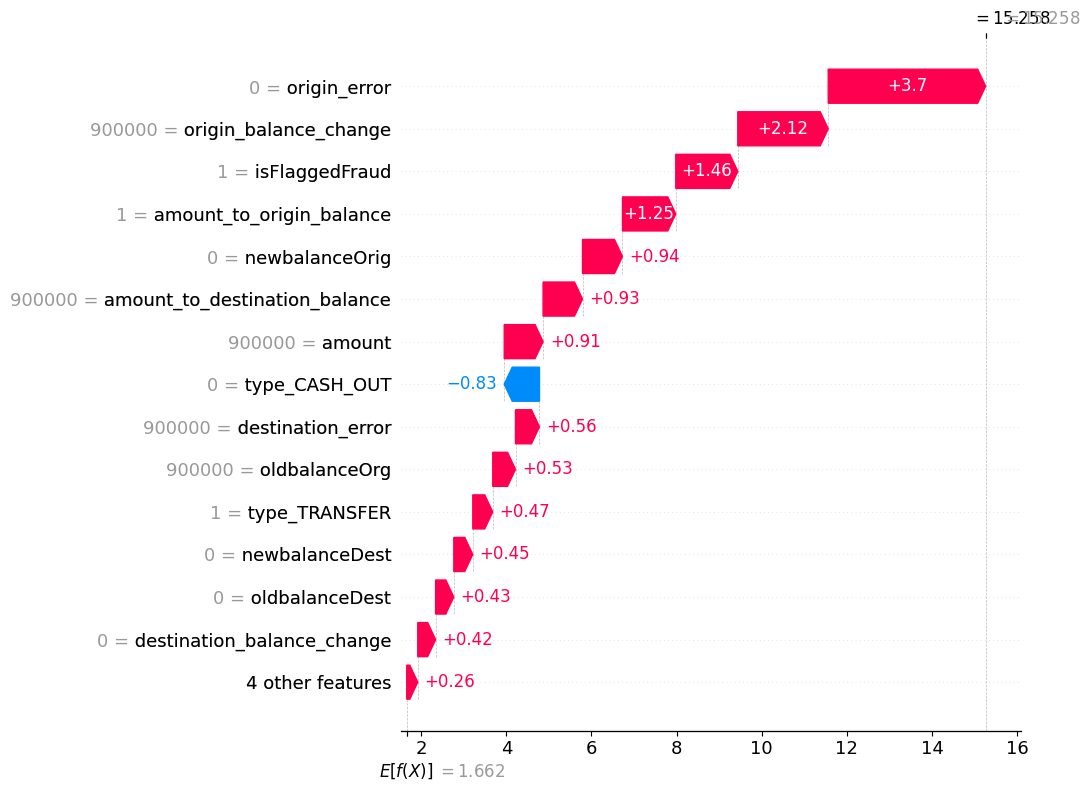

In [40]:
shap.plots.waterfall(
    result["shap_values"][0],
    max_display=15
)

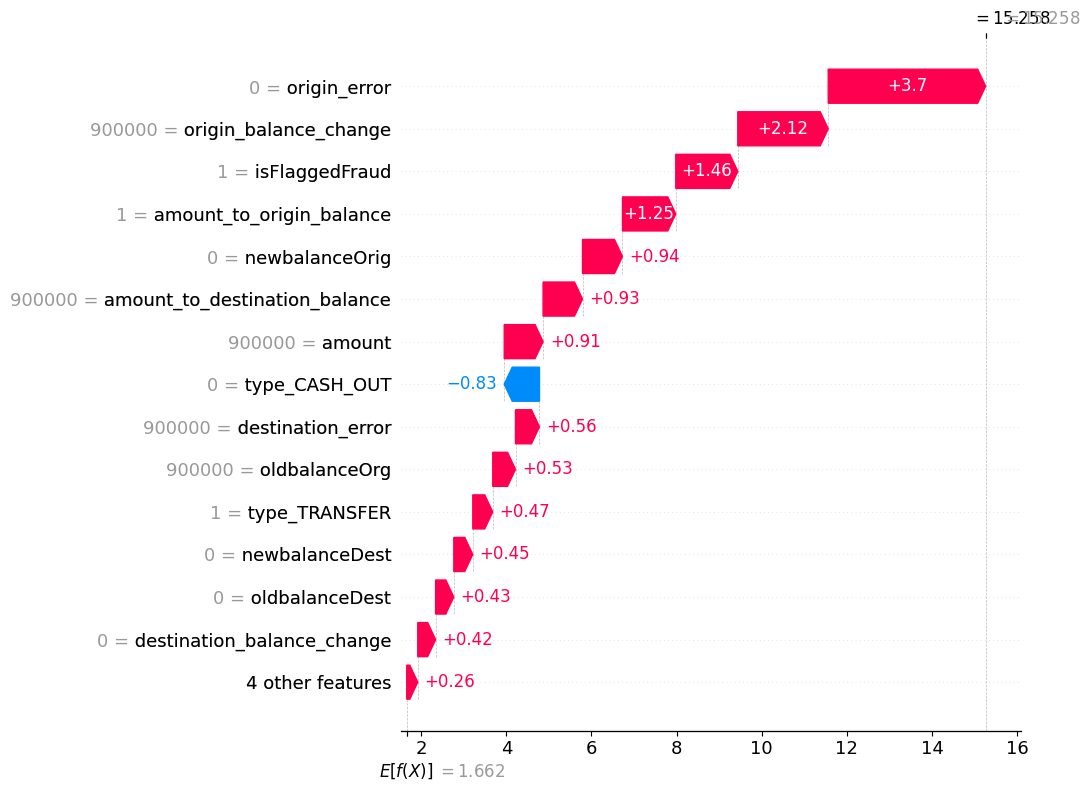

In [41]:
REPORT_DIR.mkdir(parents=True, exist_ok=True)

shap.plots.waterfall(
    result["shap_values"][0],
    max_display=15,
    show=False
)

plt.savefig(
    REPORT_DIR / "paysim_test_waterfall.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

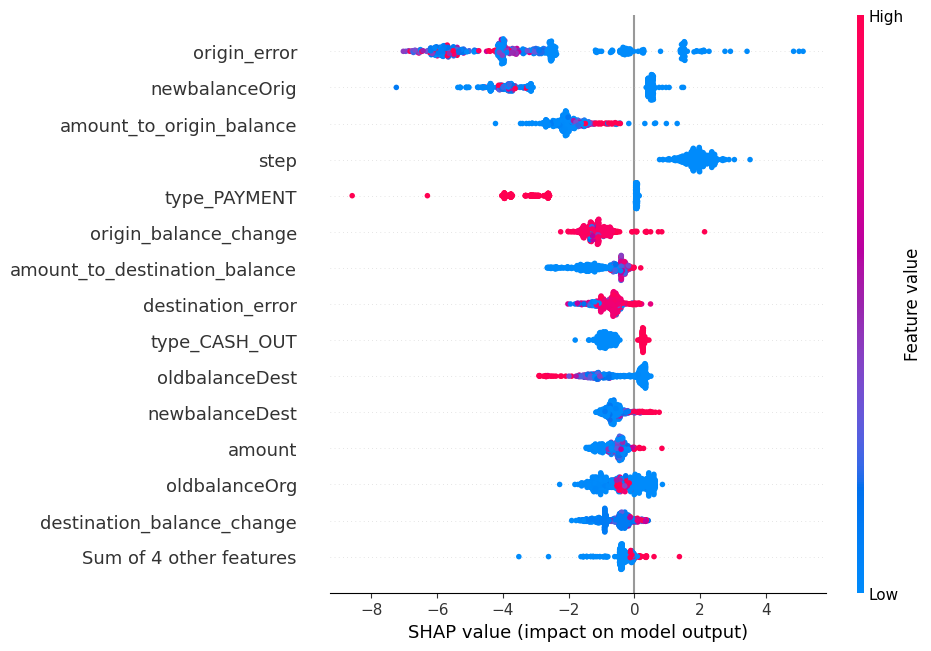

In [42]:
# Use the prepared X and y from your earlier notebook cells.
X_sample = X.sample(
    n=min(500, len(X)),
    random_state=42
)

sample_explanation = explainer(X_sample)

shap.plots.beeswarm(
    sample_explanation,
    max_display=15
)

In [43]:

# Convert SHAP values into a simple text explanation

contributions = pd.DataFrame({
    "feature": feature_names,
    "value": X_test.iloc[0].values,
    "shap_value": result["shap_values"].values[0]
})

contributions["impact"] = contributions["shap_value"].abs()

contributions = contributions.sort_values(
    "impact",
    ascending=False
)

print("FINSHIELD AI - FRAUD EXPLANATION")
print("=" * 40)

print(
    f"Fraud probability: "
    f"{result['fraud_probability']:.2%}"
)

print(
    f"Risk score: {result['risk_score']}/100"
)

print("\nWhy did the model make this prediction?")

for _, row in contributions.head(5).iterrows():

    feature = row["feature"]
    value = row["value"]
    shap_value = row["shap_value"]

    if shap_value > 0:
        direction = "increased the model's fraud prediction"
    elif shap_value < 0:
        direction = "decreased the model's fraud prediction"
    else:
        direction = "had almost no effect on the prediction"

    print(
        f"- {feature}: value = {value}, "
        f"SHAP contribution = {shap_value:.4f}; "
        f"{direction}."
    )


FINSHIELD AI - FRAUD EXPLANATION
Fraud probability: 100.00%
Risk score: 100.0/100

Why did the model make this prediction?
- origin_error: value = 0.0, SHAP contribution = 3.6976; increased the model's fraud prediction.
- origin_balance_change: value = 900000.0, SHAP contribution = 2.1240; increased the model's fraud prediction.
- isFlaggedFraud: value = 1.0, SHAP contribution = 1.4568; increased the model's fraud prediction.
- amount_to_origin_balance: value = 0.9999988888901234, SHAP contribution = 1.2516; increased the model's fraud prediction.
- newbalanceOrig: value = 0.0, SHAP contribution = 0.9386; increased the model's fraud prediction.


In [44]:

feature_descriptions = {
    "amount": "Transaction amount",
    "oldbalanceOrg": "Sender balance before transaction",
    "newbalanceOrig": "Sender balance after transaction",
    "oldbalanceDest": "Receiver balance before transaction",
    "newbalanceDest": "Receiver balance after transaction",
    "isFlaggedFraud": "Existing fraud flag",
    "origin_balance_change": "Change in sender balance",
    "destination_balance_change": "Change in receiver balance",
    "origin_error": "Difference between amount and sender balance change",
    "destination_error": "Difference between amount and receiver balance change",
    "amount_to_origin_balance": "Transaction amount relative to sender balance",
    "amount_to_destination_balance": "Transaction amount relative to receiver balance",
    "type_TRANSFER": "Transfer transaction type",
    "type_CASH_IN": "Cash-in transaction type",
    "type_CASH_OUT": "Cash-out transaction type",
    "type_DEBIT": "Debit transaction type",
    "type_PAYMENT": "Payment transaction type",
    "step": "Transaction time step"
}

print("FINSHIELD AI - EXPLANATION FOR INVESTIGATOR")
print("=" * 48)

for _, row in contributions.head(5).iterrows():

    name = feature_descriptions.get(
        row["feature"],
        row["feature"]
    )

    if row["shap_value"] > 0:
        direction = "pushed the prediction toward fraud"
    elif row["shap_value"] < 0:
        direction = "pushed the prediction away from fraud"
    else:
        direction = "had negligible influence"

    print(f"{name}: {direction}.")


FINSHIELD AI - EXPLANATION FOR INVESTIGATOR
Difference between amount and sender balance change: pushed the prediction toward fraud.
Change in sender balance: pushed the prediction toward fraud.
Existing fraud flag: pushed the prediction toward fraud.
Transaction amount relative to sender balance: pushed the prediction toward fraud.
Sender balance after transaction: pushed the prediction toward fraud.


In [45]:
transaction = {
    "step": 500,
    "amount": 900000,
    "oldbalanceOrg": 900000,
    "newbalanceOrig": 0,
    "oldbalanceDest": 0,
    "newbalanceDest": 0,
    "isFlaggedFraud": 1,
    "origin_balance_change": 900000,
    "destination_balance_change": 0,
    "origin_error": 0,
    "destination_error": 900000,
    "amount_to_origin_balance": 900000 / 900001,
    "amount_to_destination_balance": 900000,
    "type_CASH_IN": 0,
    "type_CASH_OUT": 0,
    "type_DEBIT": 0,
    "type_PAYMENT": 0,
    "type_TRANSFER": 1
}

X_test = pd.DataFrame([transaction])[feature_names]

print("Test transaction ready:", X_test.shape)

Test transaction ready: (1, 18)


In [46]:
result = explain_transaction(
    model,
    explainer,
    feature_names,
    X_test
)

print("Fraud probability:", result["fraud_probability"])
print("Risk score:", result["risk_score"], "/100")

Fraud probability: 1.0
Risk score: 100.0 /100


In [47]:
contributions = pd.DataFrame({
    "feature": feature_names,
    "value": X_test.iloc[0].values,
    "shap_value": result["shap_values"].values[0]
})

contributions["impact"] = contributions["shap_value"].abs()

contributions = contributions.sort_values(
    "impact",
    ascending=False
)

feature_descriptions = {
    "amount": "Transaction amount",
    "oldbalanceOrg": "Sender balance before transaction",
    "newbalanceOrig": "Sender balance after transaction",
    "oldbalanceDest": "Receiver balance before transaction",
    "newbalanceDest": "Receiver balance after transaction",
    "isFlaggedFraud": "Existing fraud flag",
    "origin_balance_change": "Change in sender balance",
    "destination_balance_change": "Change in receiver balance",
    "origin_error": "Sender balance difference",
    "destination_error": "Receiver balance difference",
    "amount_to_origin_balance": "Amount relative to sender balance",
    "amount_to_destination_balance": "Amount relative to receiver balance",
    "type_TRANSFER": "Transfer transaction type",
    "type_CASH_IN": "Cash-in transaction type",
    "type_CASH_OUT": "Cash-out transaction type",
    "type_DEBIT": "Debit transaction type",
    "type_PAYMENT": "Payment transaction type",
    "step": "Transaction time step"
}

print("\nFINSHIELD AI — TRANSACTION EXPLANATION")
print("=" * 48)
print(f"Fraud probability: {result['fraud_probability']:.2%}")
print(f"Risk score: {result['risk_score']}/100")

print("\nTop contributing features:")

for _, row in contributions.head(5).iterrows():
    name = feature_descriptions.get(
        row["feature"], row["feature"]
    )

    if row["shap_value"] > 0:
        direction = "pushed the prediction toward fraud"
    elif row["shap_value"] < 0:
        direction = "pushed the prediction away from fraud"
    else:
        direction = "had negligible influence"

    print(
        f"- {name}: {direction} "
        f"(SHAP value: {row['shap_value']:.4f})"
    )


FINSHIELD AI — TRANSACTION EXPLANATION
Fraud probability: 100.00%
Risk score: 100.0/100

Top contributing features:
- Sender balance difference: pushed the prediction toward fraud (SHAP value: 3.6976)
- Change in sender balance: pushed the prediction toward fraud (SHAP value: 2.1240)
- Existing fraud flag: pushed the prediction toward fraud (SHAP value: 1.4568)
- Amount relative to sender balance: pushed the prediction toward fraud (SHAP value: 1.2516)
- Sender balance after transaction: pushed the prediction toward fraud (SHAP value: 0.9386)
